# Maze-topology ablation: does the metapolicy-GPI gap need walls?

Four domains in, only Office showed a real gap between the restricted, iterated
metapolicy and full GPI (`03_adaptive_basis.ipynb` -> DST: ceiling; `office_rmvi_comparison.ipynb`
-> real gap, closed by pooling; `04_resource_gathering.ipynb` -> no gap; `05_double_slit.ipynb`
-> no gap despite genuine stochasticity). The one structural feature Office has that the
other three don't: **internal walls carving the map into rooms connected by narrow
doorways**, forcing multiple routes to converge onto shared corridors.

The mechanism this predicts: metapolicy's restriction at a state `s` is to `B(s) =
{pi_1(s), ..., pi_k(s)}` -- each base policy's OWN greedy action. GPI, by contrast, can
take *any* action `a` and score it by `max_j Psi_j(s,a).w` -- "take `a`, then evaluate
as if reverting to whichever base policy's TAIL is best from there." That only pays off
when some action *not* prescribed by any policy's own greedy choice still lands you on
a state/corridor another policy's trajectory would *also* naturally pass through -- i.e.
when routes converge. Open fields and single corridors (DST, Resource Gathering, Double
Slit) rarely offer this; a multi-room maze with shared doorways plausibly does.

This notebook tests that directly: **one grid, one set of reward positions, walls
on vs. walls off** -- so wall topology is the only thing that changes between the two
runs. If the gap appears only with walls, that's real evidence for the mechanism, not
just a post-hoc story about Office's specific maze.

## 1. A minimal 4-room maze, and its walls-off control

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

np.set_printoptions(suppress=True, precision=4)

GAMMA = 0.99
SEED = 0
N_ACTIONS = 4  # up, down, left, right
GRID = 11      # rows 0..10, cols 0..10
DIR = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}

START = (7, 1)
REWARDS = {0: (2, 2), 1: (2, 8), 2: (8, 8)}  # room TL, TR, BR -- start is in room BL
FEAT_DIM = len(REWARDS)


def build_occupied(walls_on):
    """Border walls always present. With walls_on, add the classic four-rooms cross
    (row 5 / col 5) with one single-cell doorway per adjoining room pair -- so REACHING
    any reward from START (room BL) requires passing through 1 or 2 narrow doorways.
    With walls_on=False, only the border remains: same rewards, same start, open field."""
    occ = set()
    for r in range(GRID):
        for c in range(GRID):
            if r == 0 or r == GRID - 1 or c == 0 or c == GRID - 1:
                occ.add((r, c))
    if walls_on:
        doorway_row = {2: 5, 8: 5}     # TL-TR doorway at (2,5), BL-BR doorway at (8,5)
        doorway_col = {2: 5, 8: 5}     # TL-BL doorway at (5,2), TR-BR doorway at (5,8)
        for c in range(1, GRID - 1):
            if c != 2 and c != 8:
                occ.add((5, c))
        for r in range(1, GRID - 1):
            if r != 2 and r != 8:
                occ.add((r, 5))
    return occ


def build_domain(walls_on):
    occupied = build_occupied(walls_on)
    states = [(r, c) for r in range(GRID) for c in range(GRID) if (r, c) not in occupied]
    state_idx = {s: i for i, s in enumerate(states)}
    is_terminal = {s: s in REWARDS.values() for s in states}
    nonterminal = [s for s in states if not is_terminal[s]]
    reward_idx = {pos: i for i, pos in REWARDS.items()}
    return dict(occupied=occupied, states=states, state_idx=state_idx,
                is_terminal=is_terminal, nonterminal=nonterminal, reward_idx=reward_idx)


def step_deterministic(dom, s, a):
    dr, dc = DIR[a]
    ns = (s[0] + dr, s[1] + dc)
    if ns in dom["occupied"] or ns not in dom["state_idx"]:
        ns = s
    terminal = ns in dom["reward_idx"]
    phi = np.zeros(FEAT_DIM)
    if terminal:
        phi[dom["reward_idx"][ns]] = 1.0
    return ns, phi, terminal

walls on:  68 states (65 non-terminal)
walls off: 81 states (78 non-terminal)


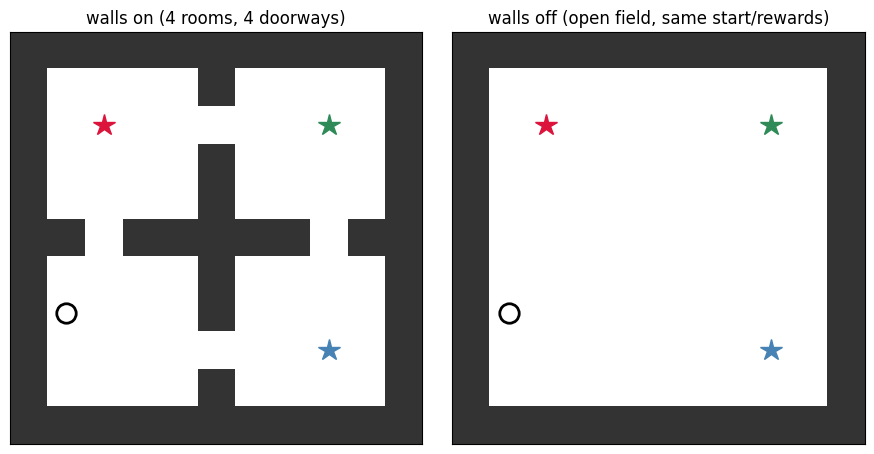

In [2]:
def plot_maze(ax, dom, title):
    grid = np.zeros((GRID, GRID))
    for (r, c) in dom["occupied"]:
        grid[r, c] = 1
    cmap = ListedColormap(["#ffffff", "#333333"])
    ax.imshow(grid, cmap=cmap, vmin=0, vmax=1, origin="upper")
    ax.plot(START[1], START[0], marker="o", markersize=14, markerfacecolor="none",
            markeredgecolor="black", markeredgewidth=2)
    colors = ["crimson", "seagreen", "steelblue"]
    for i, pos in REWARDS.items():
        ax.plot(pos[1], pos[0], marker="*", markersize=16, color=colors[i])
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title)


dom_walls = build_domain(walls_on=True)
dom_open = build_domain(walls_on=False)
print(f"walls on:  {len(dom_walls['states'])} states ({len(dom_walls['nonterminal'])} non-terminal)")
print(f"walls off: {len(dom_open['states'])} states ({len(dom_open['nonterminal'])} non-terminal)")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
plot_maze(axes[0], dom_walls, "walls on (4 rooms, 4 doorways)")
plot_maze(axes[1], dom_open, "walls off (open field, same start/rewards)")
plt.tight_layout()
plt.show()

## 2. Exact solvers, GPI vs. metapolicy vs. pool-fed-back GPI -- parameterized by domain

In [3]:
class SFTable:
    def __init__(self, num_actions, feat_dim, default_vec):
        self.default_vec = default_vec
        self.table = {}

    def __getitem__(self, state):
        if state not in self.table:
            self.table[state] = self.default_vec.copy()
        return self.table[state]


def policy_iteration(dom, w, gamma=GAMMA):
    states, state_idx, nonterminal = dom["states"], dom["state_idx"], dom["nonterminal"]
    n = len(states)
    policy = {s: 0 for s in nonterminal}
    while True:
        A, b = np.eye(n), np.zeros(n)
        for s in nonterminal:
            i = state_idx[s]
            ns, phi, term = step_deterministic(dom, s, policy[s])
            b[i] = phi @ w
            if not term:
                A[i, state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[state_idx[s]] for s in states}
        stable = True
        for s in nonterminal:
            qs = []
            for a in range(N_ACTIONS):
                ns, phi, term = step_deterministic(dom, s, a)
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_a = int(np.argmax(qs))
            stable &= best_a == policy[s]
            policy[s] = best_a
        if stable:
            return policy, V


def solve_task_exact(dom, w, gamma=GAMMA):
    states, state_idx, nonterminal = dom["states"], dom["state_idx"], dom["nonterminal"]
    n = len(states)
    policy, _ = policy_iteration(dom, w, gamma)
    A, b = np.eye(n), np.zeros((n, FEAT_DIM))
    for s in nonterminal:
        i = state_idx[s]
        ns, phi, term = step_deterministic(dom, s, policy[s])
        b[i] = phi
        if not term:
            A[i, state_idx[ns]] -= gamma
    V_vec = np.linalg.solve(A, b)
    V_vec = {s: V_vec[state_idx[s]] for s in states}

    psi = SFTable(N_ACTIONS, FEAT_DIM, np.zeros((N_ACTIONS, FEAT_DIM)))
    for s in nonterminal:
        table = np.zeros((N_ACTIONS, FEAT_DIM))
        for a in range(N_ACTIONS):
            ns, phi, term = step_deterministic(dom, s, a)
            table[a] = phi if term else phi + gamma * V_vec[ns]
        psi.table[s] = table
    return psi


def evaluate_fixed_policy_scalar(dom, action_fn, w, gamma=GAMMA):
    states, state_idx, nonterminal = dom["states"], dom["state_idx"], dom["nonterminal"]
    n = len(states)
    A, b = np.eye(n), np.zeros(n)
    for s in nonterminal:
        i = state_idx[s]
        ns, phi, term = step_deterministic(dom, s, action_fn(s))
        b[i] = phi @ w
        if not term:
            A[i, state_idx[ns]] -= gamma
    v = np.linalg.solve(A, b)
    return {s: v[state_idx[s]] for s in states}


def own_greedy_actions(dom, sf_table, w):
    return {s: int(np.argmax(sf_table[s] @ w)) for s in dom["nonterminal"]}


def meta_policy_iteration_warm(dom, w, Pi_base, W_base, gamma=GAMMA, gpi_init=True, max_sweeps=500):
    states, state_idx, nonterminal = dom["states"], dom["state_idx"], dom["nonterminal"]
    n = len(states)
    own_actions = [own_greedy_actions(dom, sft, w_j) for sft, w_j in zip(Pi_base, W_base)]
    if gpi_init:
        meta_policy = {}
        for s in nonterminal:
            vals = [Pi_base[j][s][own_actions[j][s]] @ w for j in range(len(Pi_base))]
            meta_policy[s] = int(np.argmax(vals))
    else:
        meta_policy = {s: 0 for s in nonterminal}

    n_sweeps = 0
    while True:
        n_sweeps += 1
        A, b = np.eye(n), np.zeros(n)
        for s in nonterminal:
            i = state_idx[s]
            ns, phi, term = step_deterministic(dom, s, own_actions[meta_policy[s]][s])
            b[i] = phi @ w
            if not term:
                A[i, state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[state_idx[s]] for s in states}
        stable = True
        for s in nonterminal:
            qs = []
            for j in range(len(Pi_base)):
                ns, phi, term = step_deterministic(dom, s, own_actions[j][s])
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_j = int(np.argmax(qs))
            stable &= best_j == meta_policy[s]
            meta_policy[s] = best_j
        if stable or n_sweeps >= max_sweeps:
            return meta_policy, V, own_actions, n_sweeps


def meta_policy_sf(dom, meta_policy, own_actions, gamma=GAMMA):
    states, state_idx, nonterminal = dom["states"], dom["state_idx"], dom["nonterminal"]
    n = len(states)
    A, b = np.eye(n), np.zeros((n, FEAT_DIM))
    for s in nonterminal:
        i = state_idx[s]
        ns, phi, term = step_deterministic(dom, s, own_actions[meta_policy[s]][s])
        b[i] = phi
        if not term:
            A[i, state_idx[ns]] -= gamma
    Psi_arr = np.linalg.solve(A, b)
    return {s: Psi_arr[state_idx[s]] for s in states}


def meta_policy_sf_full(dom, meta_policy, own_actions, gamma=GAMMA, Psi_own=None):
    if Psi_own is None:
        Psi_own = meta_policy_sf(dom, meta_policy, own_actions, gamma)
    table = SFTable(N_ACTIONS, FEAT_DIM, np.zeros((N_ACTIONS, FEAT_DIM)))
    for s in dom["nonterminal"]:
        full = np.zeros((N_ACTIONS, FEAT_DIM))
        for a in range(N_ACTIONS):
            ns, phi, term = step_deterministic(dom, s, a)
            full[a] = phi if term else phi + gamma * Psi_own[ns]
        table.table[s] = full
    return table


def bellman_gap(dom, w, V_meta, gamma=GAMMA):
    gaps = {}
    for s in dom["nonterminal"]:
        qs = []
        for a in range(N_ACTIONS):
            ns, phi, term = step_deterministic(dom, s, a)
            qs.append(phi @ w + (0.0 if term else gamma * V_meta[ns]))
        gaps[s] = max(qs) - V_meta[s]
    return gaps


def gpi_full_actions(dom, Pi, w):
    actions = {}
    for s in dom["nonterminal"]:
        vals = [max(psi[s][a] @ w for psi in Pi) for a in range(N_ACTIONS)]
        actions[s] = int(np.argmax(vals))
    return actions


def gpi_value(dom, Pi_snapshot, w, gamma=GAMMA):
    actions = gpi_full_actions(dom, Pi_snapshot, w)
    return evaluate_fixed_policy_scalar(dom, lambda s: actions[s], w, gamma)


def metapolicy_value(dom, Pi_base, W_base, w, gamma=GAMMA):
    _, V, _, _ = meta_policy_iteration_warm(dom, w, Pi_base, W_base, gamma)
    return V

## 3. GPI vs. metapolicy vs. pool-fed-back GPI, walls on vs. walls off

Same canonical-corner-basis design as the other three domains, run once per condition
(`dom_walls`, `dom_open`), everything else (rewards, start, gamma, test weights, build
weights) held fixed.

In [4]:
def grow_pool_with_metapolicy_feedback(dom, Pi_base, W_base, build_weights, gamma=GAMMA, cert_tol=1e-6):
    Pi_base, W_base = list(Pi_base), list(W_base)
    n_added = 0
    for w in build_weights:
        meta_policy, V, own_actions, _ = meta_policy_iteration_warm(dom, w, Pi_base, W_base, gamma)
        worst_gap = max(bellman_gap(dom, w, V, gamma).values())
        if worst_gap <= cert_tol:
            Psi_own = meta_policy_sf(dom, meta_policy, own_actions, gamma)
            Pi_base.append(meta_policy_sf_full(dom, meta_policy, own_actions, gamma, Psi_own=Psi_own))
            W_base.append(w)
            n_added += 1
    return Pi_base, W_base, n_added


def run_condition(dom, label):
    t0 = time.perf_counter()
    Pi_canon, W_canon = [], []
    for i in range(FEAT_DIM):
        w_i = np.zeros(FEAT_DIM)
        w_i[i] = 1.0
        Pi_canon.append(solve_task_exact(dom, w_i))
        W_canon.append(w_i)

    rng_w = np.random.default_rng(SEED)
    test_weights = [rng_w.dirichlet(np.ones(FEAT_DIM)) for _ in range(150)]
    rng_build = np.random.default_rng(SEED + 1)
    build_weights = [rng_build.dirichlet(np.ones(FEAT_DIM)) for _ in range(30)]

    def mean_value(value_fn):
        return float(np.mean([value_fn(w)[START] for w in test_weights]))

    optimal_mean = mean_value(lambda w: policy_iteration(dom, w)[1])

    ks = np.arange(1, FEAT_DIM + 1)
    gpi_curve, metapolicy_curve, pooled_curve, pool_sizes = [], [], [], []
    for k in ks:
        Pi_k, W_k = Pi_canon[:k], W_canon[:k]
        gpi_curve.append(mean_value(lambda w, Pi_k=Pi_k: gpi_value(dom, Pi_k, w)))
        metapolicy_curve.append(mean_value(lambda w, Pi_k=Pi_k, W_k=W_k: metapolicy_value(dom, Pi_k, W_k, w)))
        Pi_grown, W_grown, n_added = grow_pool_with_metapolicy_feedback(dom, Pi_k, W_k, build_weights)
        pooled_curve.append(mean_value(lambda w, Pi=Pi_grown: gpi_value(dom, Pi, w)))
        pool_sizes.append(len(Pi_grown))
        print(f"[{label}] k={k}: GPI={gpi_curve[-1]:.4f}  metapolicy={metapolicy_curve[-1]:.4f}  "
              f"pooled+GPI={pooled_curve[-1]:.4f}  (pool grew {k}->{len(Pi_grown)}, {n_added}/30 added)")

    print(f"[{label}] optimal_mean={optimal_mean:.4f}  computed in {time.perf_counter()-t0:.1f}s")
    return dict(ks=ks, gpi=gpi_curve, metapolicy=metapolicy_curve, pooled=pooled_curve,
                pool_sizes=pool_sizes, optimal=optimal_mean)


results_walls = run_condition(dom_walls, "walls-on ")
results_open = run_condition(dom_open, "walls-off")

[walls-on ] k=1: GPI=0.3188  metapolicy=0.3188  pooled+GPI=0.3188  (pool grew 1->8, 7/30 added)


[walls-on ] k=2: GPI=0.4724  metapolicy=0.4724  pooled+GPI=0.4724  (pool grew 2->22, 20/30 added)


[walls-on ] k=3: GPI=0.5516  metapolicy=0.5516  pooled+GPI=0.5516  (pool grew 3->33, 30/30 added)
[walls-on ] optimal_mean=0.5516  computed in 9.9s


[walls-off] k=1: GPI=0.3188  metapolicy=0.3188  pooled+GPI=0.3188  (pool grew 1->8, 7/30 added)


[walls-off] k=2: GPI=0.4724  metapolicy=0.4724  pooled+GPI=0.4724  (pool grew 2->22, 20/30 added)


[walls-off] k=3: GPI=0.5516  metapolicy=0.5516  pooled+GPI=0.5516  (pool grew 3->33, 30/30 added)
[walls-off] optimal_mean=0.5516  computed in 13.5s


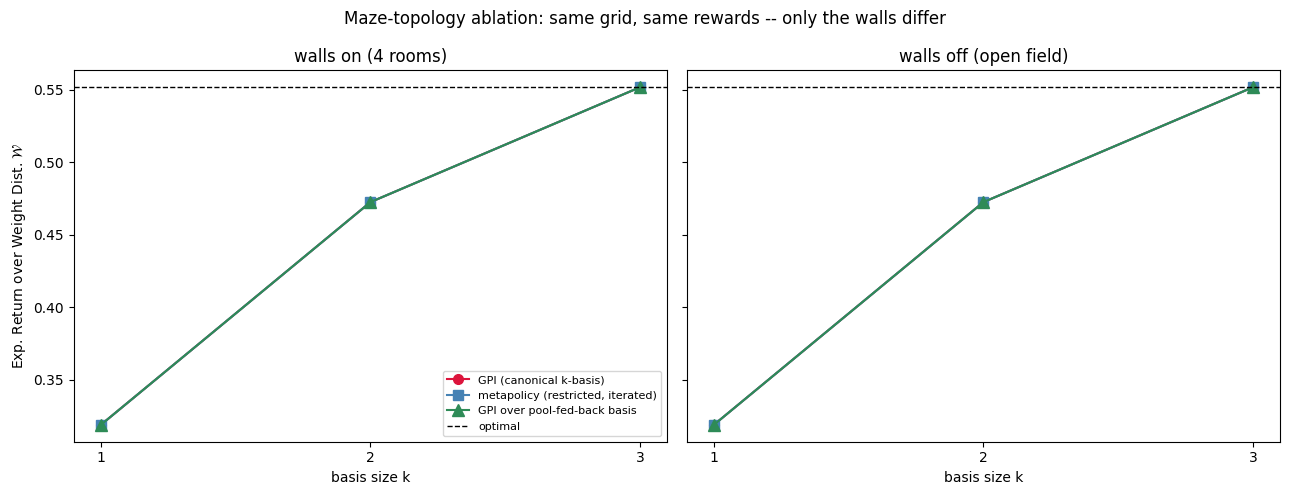

 condition   k    GPI gap   metapolicy gap   pooled gap
  walls-on   1     0.2329           0.2329       0.2329
  walls-on   2     0.0792           0.0792       0.0792
  walls-on   3     0.0000           0.0000       0.0000
 walls-off   1     0.2329           0.2329       0.2329
 walls-off   2     0.0792           0.0792       0.0792
 walls-off   3     0.0000           0.0000       0.0000

max metapolicy-vs-optimal gap, walls on:  0.2329
max metapolicy-vs-optimal gap, walls off: 0.2329


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, res, title in [(axes[0], results_walls, "walls on (4 rooms)"), (axes[1], results_open, "walls off (open field)")]:
    ax.plot(res["ks"], res["gpi"], marker="o", ms=7, color="crimson", label="GPI (canonical k-basis)")
    ax.plot(res["ks"], res["metapolicy"], marker="s", ms=7, color="steelblue", label="metapolicy (restricted, iterated)")
    ax.plot(res["ks"], res["pooled"], marker="^", ms=8, color="seagreen", label="GPI over pool-fed-back basis")
    ax.axhline(res["optimal"], color="black", ls="--", lw=1, label="optimal")
    ax.set_xlabel("basis size k")
    ax.set_xticks(res["ks"])
    ax.set_title(title)
axes[0].set_ylabel(r"Exp. Return over Weight Dist. $\mathcal{W}$")
axes[0].legend(fontsize=8)
fig.suptitle("Maze-topology ablation: same grid, same rewards -- only the walls differ")
plt.tight_layout()
plt.show()

print(f"{'condition':>10} {'k':>3} {'GPI gap':>10} {'metapolicy gap':>16} {'pooled gap':>12}")
for label, res in [("walls-on", results_walls), ("walls-off", results_open)]:
    for k, g, m, p in zip(res["ks"], res["gpi"], res["metapolicy"], res["pooled"]):
        opt = res["optimal"]
        print(f"{label:>10} {k:>3} {opt-g:>10.4f} {opt-m:>16.4f} {opt-p:>12.4f}")

max_gap_walls = max(o - m for o, m in zip([results_walls["optimal"]] * len(results_walls["ks"]), results_walls["metapolicy"]))
max_gap_open = max(o - m for o, m in zip([results_open["optimal"]] * len(results_open["ks"]), results_open["metapolicy"]))
print(f"\nmax metapolicy-vs-optimal gap, walls on:  {max_gap_walls:.4f}")
print(f"max metapolicy-vs-optimal gap, walls off: {max_gap_open:.4f}")